# 03. Praktyczne zastosowania

**Poziom: Praktyczne użycia**


## Spis treści

- [Problem](#sekcja-01)
- [Po tej części potrafisz](#sekcja-02)
- [Wykonanie](#sekcja-03)
- [1. Zastosowanie: konfiguracja](#sekcja-04)
    - [Demonstracja: Ustawienia o różnych typach](#sekcja-05)
- [2. Zastosowanie: sukces albo błąd](#sekcja-06)
    - [Demonstracja: Sukces i trzy rodzaje błędów](#sekcja-07)
- [3. Maszyna stanów: reakcja zależy od stanu i zdarzenia](#sekcja-08)
    - [Ta sama informacja może mieć różny sens w różnych stanach](#sekcja-09)
    - [Co z kombinacjami bez własnej reguły?](#sekcja-10)
    - [Jak przeczytać wynik programu?](#sekcja-11)
    - [Demonstracja: Przejścia między stanami połączenia](#sekcja-12)
- [Artykuły i dokumentacja](#sekcja-13)
    - [Artykuły z przykładami](#sekcja-14)
    - [Dokumentacja konkretnych operacji](#sekcja-15)


<a id="sekcja-01"></a>

## Problem

Łączymy poznane mechanizmy w historię klienta API: przechowujemy jego ustawienia, odczytujemy liczbę prób z tekstu, a następnie symulujemy stany połączenia z serwerem `example.org`. Każda demonstracja jest samodzielna i nie wykonuje połączeń sieciowych.

<a id="sekcja-02"></a>

## Po tej części potrafisz

- Opisać ustawienia o różnych typach bez ręcznej flagi.
- Odróżnić sukces od błędu operacji za pomocą nazwanych struktur.
- Prześledzić przejścia zależne od pary stan i zdarzenie.

<a id="sekcja-03"></a>

## Wykonanie

Wybierz kernel Python 3 i wykonaj komórki od góry. Poniższa komórka Python przygotowuje `%%cpp`; każda komórka C++ zawiera własne nagłówki, definicje i `main()`. W razie problemu wróć do [sprawdzenia środowiska](00_start.ipynb).


In [1]:
import os
import shutil
import subprocess
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.core.magic import register_cell_magic

COMPILER_NAME = os.environ.get("CXX", "c++")

@register_cell_magic
def cpp(line: str, cell: str) -> None:
    """Kompiluje i uruchamia jedną niezależną demonstrację C++17."""
    option = line.strip()
    if option not in {"", "--expect-error"}:
        raise ValueError("Użyj %%cpp albo %%cpp --expect-error.")
    expect_error = option == "--expect-error"
    compiler = shutil.which(COMPILER_NAME)
    if compiler is None:
        raise RuntimeError(
            f"Nie znaleziono kompilatora {COMPILER_NAME!r}. "
            "Zainstaluj kompilator C++17 lub ustaw COMPILER_NAME."
        )
    with TemporaryDirectory(prefix="variant-notebook-") as directory:
        source = Path(directory) / "example.cpp"
        executable = Path(directory) / ("example.exe" if os.name == "nt" else "example")
        source.write_text(cell, encoding="utf-8")
        compiled = subprocess.run(
            [compiler, "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
             str(source), "-o", str(executable)],
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60,
        )
        if expect_error:
            if compiled.returncode == 0:
                raise RuntimeError("Oczekiwano błędu kompilacji, ale program skompilował się poprawnie.")
            print("Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:")
            diagnostics = (compiled.stdout + compiled.stderr).replace(str(source), "example.cpp").splitlines()
            print("\n".join(diagnostics[:16]))
            if len(diagnostics) > 16:
                print("[Dalsza część komunikatu została pominięta.]")
            return
        if compiled.returncode != 0:
            raise RuntimeError("Błąd kompilacji:\n" + compiled.stdout + compiled.stderr)
        executed = subprocess.run(
            [str(executable)], capture_output=True, text=True,
            encoding="utf-8", errors="replace", timeout=10,
        )
        print(executed.stdout, end="")
        if executed.stderr:
            print(executed.stderr, end="")
        if executed.returncode != 0:
            raise RuntimeError(f"Program zakończył się kodem {executed.returncode}.")

print(f"Gotowe: %%cpp używa {COMPILER_NAME}, standard C++17.")

Gotowe: %%cpp używa c++, standard C++17.


<a id="sekcja-04"></a>

## 1. Zastosowanie: konfiguracja

Pierwszy etap historii przechowuje ustawienia klienta API w `std::map<std::string, ConfigValue>`. Każdy wpis ma nazwę i jedną wartość, a odwiedzający wypisuje ją niezależnie od aktywnego typu.

Jawne `std::string{"localhost"}` pokazuje zamierzony typ, bez polegania na szczegółach konwersji literału tekstowego. Mapa zapewnia tutaj kolejność po kluczach; `variant` nie odpowiada za kolejność wpisów.

Taki model zapobiega niezgodności ręcznej flagi i typu wartości. **Nie sprawdza jednak reguł konfiguracji:** nadal można przypisać tekst do klucza `retries`. Regułę „ten klucz wymaga liczby nieujemnej” trzeba zrealizować osobno. Dla z góry ustalonego zestawu ustawień zwykła struktura z nazwanymi polami może być lepsza.


<a id="sekcja-05"></a>

### Demonstracja: Ustawienia o różnych typach

Wykonaj komórkę, aby zobaczyć wspólne wypisywanie ustawień logicznych, liczbowych i tekstowych.


In [2]:
%%cpp
// Cel: konfiguracja z zamkniętym zbiorem typów i deterministyczną kolejnością.
#include <iostream>
#include <map>
#include <string>
#include <variant>

int main() {
    using ConfigValue = std::variant<bool, int, std::string>;
    const std::map<std::string, ConfigValue> config{
        {"debug", true}, {"retries", 3}, {"server", std::string{"example.org"}}
    };
    std::cout << std::boolalpha;
    for (const auto& entry : config) {
        std::cout << entry.first << " = ";
        std::visit(
            [](const auto& x) {
                std::cout << x;
            },
            entry.second
        );
        std::cout << '\n';
    }
}


debug = true
retries = 3
server = example.org


**Jak czytać wynik:** Każdy wpis konfiguracji ma ten sam typ `ConfigValue`, ale przechowuje inną alternatywę. `std::map` porządkuje klucze, a `boolalpha` wypisuje wartość logiczną jako `true`.


<a id="sekcja-06"></a>

## 2. Zastosowanie: sukces albo błąd

Drugi etap odczytuje z tekstu liczbę prób połączenia. Wynik parsowania ma postać:


In [3]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct Success {
    int value;
};
struct Error {
    std::string message;
};
using Result = std::variant<Success, Error>;

int main() {
    Result wynik{Success{3}};
    std::cout << std::get<Success>(wynik).value << '\n';
    wynik = Error{"brak cyfr"};
    std::cout << std::get<Error>(wynik).message << '\n';
}


3
brak cyfr


Zamiast utrzymywać liczbę, flagę sukcesu i komunikat w trzech niezależnych polach, zwracamy jednoznaczny przypadek. Odwiedzający dostaje wartość sukcesu albo opis błędu.

Program używa `std::stoi`: przechwytuje brak poprawnej liczby oraz przekroczenie zakresu, a dodatkowo sprawdza liczbę zużytych znaków. Dzięki temu `12x` nie zostaje zaakceptowane jako pełny zapis liczby 12.

To celowo niewielki parser: dziedziczy akceptowanie początkowych białych znaków i znaku `+`/`-` z `stoi`; końcowe znaki, również spacje, odrzuca. Nie służy do definiowania uniwersalnego formatu liczb.

Zwracanie `Result` opisuje przewidywane wyniki operacji, ale nie daje gwarancji braku wszelkich wyjątków - np. tworzenie tekstu błędu może wymagać alokacji. W C++23 istnieje `std::expected<T, E>` przeznaczone do modelu wartość albo błąd; w tym pakiecie pozostajemy przy C++17.


<a id="sekcja-07"></a>

### Demonstracja: Sukces i trzy rodzaje błędów

Komórka przetwarza poprawną liczbę, tekst bez cyfr, liczbę z końcowymi znakami oraz wartość poza zakresem `int`.


In [4]:
%%cpp
// Cel: sukces i błąd jako rozłączne wyniki; parser akceptuje całe wejscie.
#include <iostream>
#include <stdexcept>
#include <string>
#include <variant>

struct Success {
    int value;
};
struct Error {
    std::string message;
};
using Result = std::variant<Success, Error>;

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

Result parse_int(const std::string& input) {
    try {
        std::size_t consumed = 0;
        const int value = std::stoi(input, &consumed);
        if (consumed != input.size()) {
            return Error{"znaki po liczbie"};
        }
        return Success{value};
    } catch (const std::invalid_argument&) {
        return Error{"brak cyfr"};
    } catch (const std::out_of_range&) {
        return Error{"liczba poza zakresem int"};
    }
}

int main() {
    const std::string inputs[] = {"3", "abc", "12x", std::string(100, '9')};
    for (const auto& input : inputs) {
        const Result result = parse_int(input);
        std::visit(
            overloaded{
                [](const Success& s) {
                    std::cout << "sukces: " << s.value << '\n';
                },
                [](const Error& e) {
                    std::cout << "blad: " << e.message << '\n';
                }
            },
            result
        );
    }
}


sukces: 3
blad: brak cyfr
blad: znaki po liczbie
blad: liczba poza zakresem int


**Jak czytać wynik:** Wejście `3` daje sukces i odpowiada liczbie prób z konfiguracji. `abc` nie zawiera liczby, `12x` pozostawia znaki po liczbie, a ciąg stu dziewiątek przekracza zakres `int`. Każdy błąd ma własny opis w alternatywie `Error`.


<a id="sekcja-08"></a>

## 3. Maszyna stanów: reakcja zależy od stanu i zdarzenia

Maszyna stanów to sposób opisania programu, którego zachowanie zależy od tego, **w jakim stanie jest teraz** oraz **co właśnie się wydarzyło**.

Trzeci etap symuluje połączenie klienta API z serwerem `example.org`. Ma trzy stany:

- `Disconnected` - nie jesteśmy połączeni.
- `Connecting` - trwa nawiązywanie połączenia; pamiętamy nazwę hosta.
- `Connected` - połączenie zostało potwierdzone; nadal pamiętamy nazwę hosta.

Osobno opisujemy zdarzenia:

- `Connect` - polecenie rozpoczęcia łączenia z podanym hostem.
- `Established` - informacja, że połączenie się udało.
- `Disconnect` - polecenie rozłączenia.

Stan i zdarzenie są dwoma różnymi wariantami. W danej chwili mamy jeden konkretny stan i przetwarzamy jedno konkretne zdarzenie.

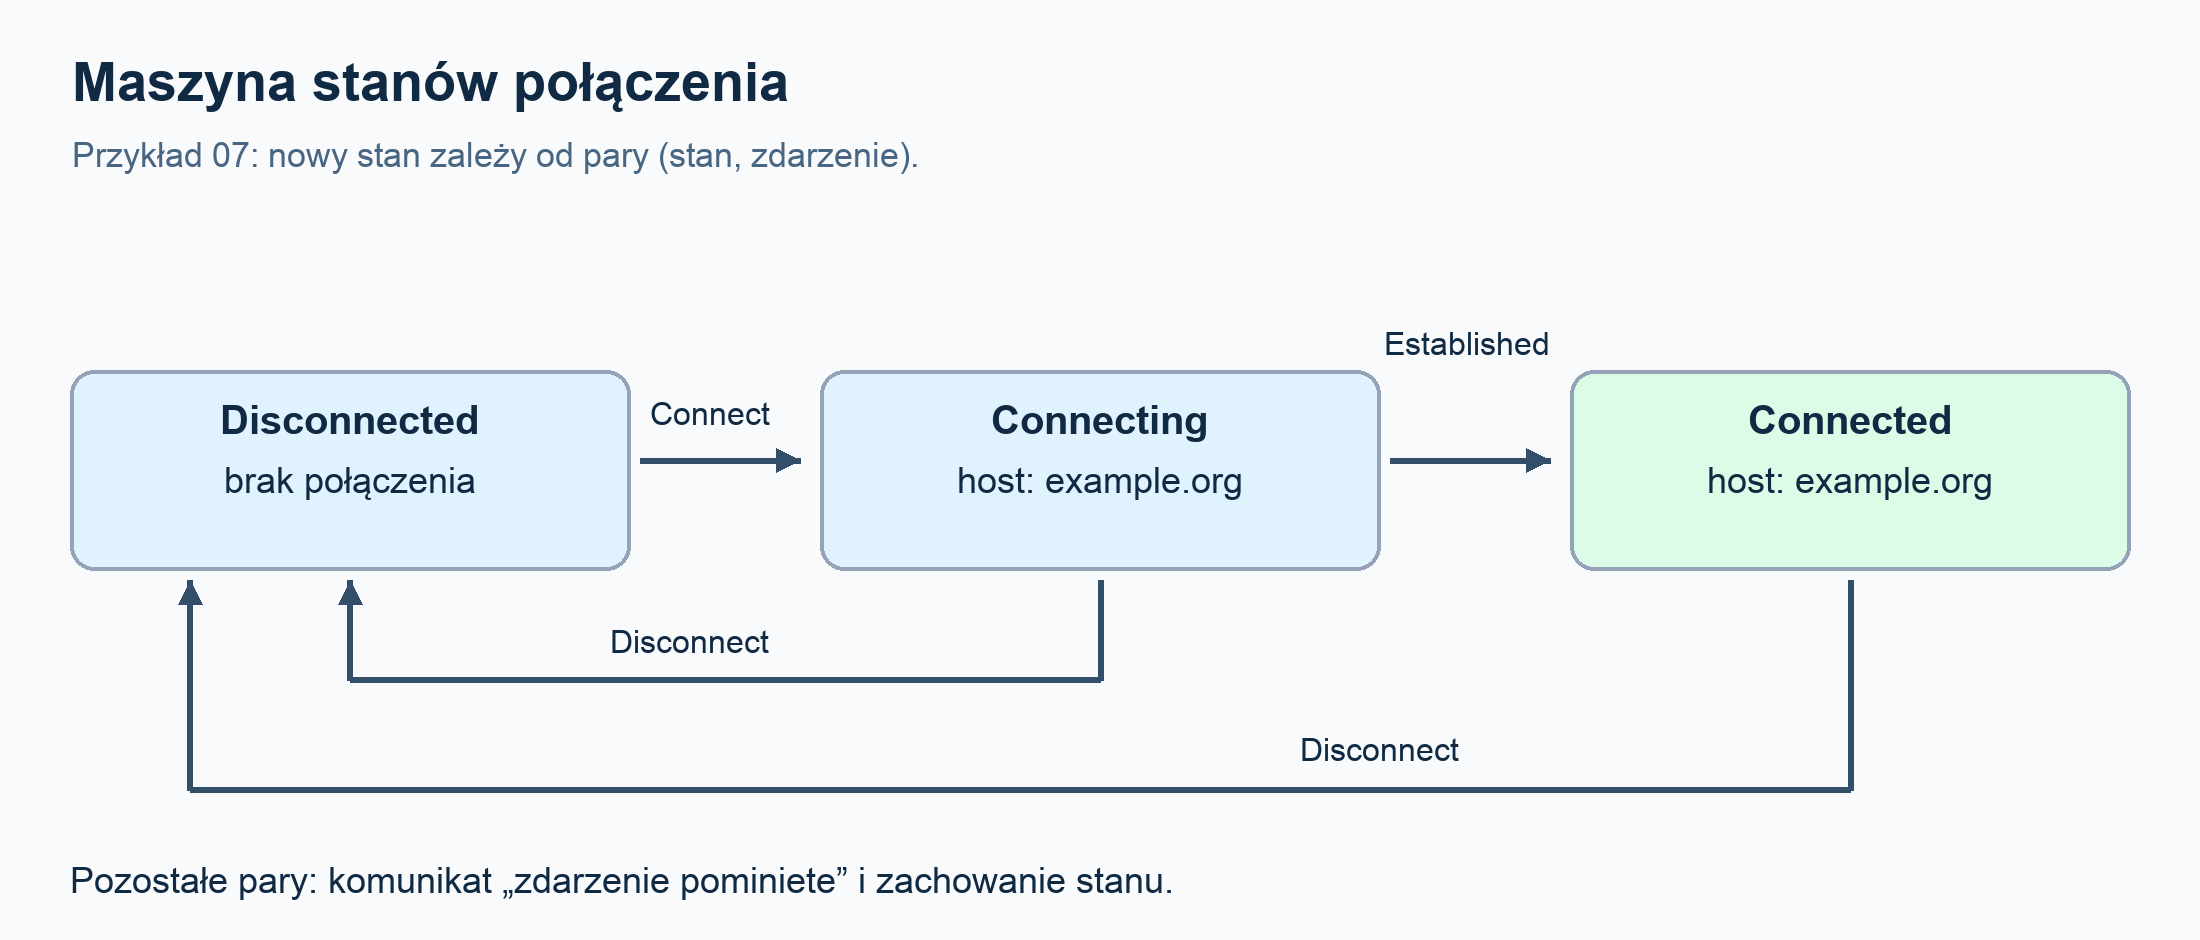

Strzałki pokazują cztery jawne reguły z `transition`. Pozostałe kombinacje obsługuje ostatnia, ogólna lambda, która zachowuje dotychczasowy stan.

<a id="sekcja-09"></a>

### Ta sama informacja może mieć różny sens w różnych stanach

Jeśli jesteśmy w `Connecting` i przychodzi `Established`, przechodzimy do `Connected`. Jeśli jesteśmy w `Disconnected` i przychodzi `Established`, ignorujemy to zdarzenie: nie rozpoczęliśmy wcześniej łączenia.

Funkcja `transition` przyjmuje stan i zdarzenie, a zwraca nowy stan. Poniższa komórka wyodrębnia jedną regułę: potwierdzenie połączenia w stanie `Connecting`.


In [5]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct Disconnected {};
struct Connecting {
    std::string host;
};
struct Connected {
    std::string host;
};
struct Established {};
using State = std::variant<Disconnected, Connecting, Connected>;

int main() {
    const auto establish = [](const Connecting& stan, const Established&) -> State {
        return Connected{stan.host};
    };
    const State state = establish(Connecting{"example.org"}, Established{});
    std::cout << std::get<Connected>(state).host << '\n';
}


example.org


Lambda `establish` pokazuje jedną z reguł odwiedzającego. Komórka zawiera też definicje typów oraz wywołanie tej lambdy. Pierwszy argument mówi, w jakim stanie jesteśmy. Drugi mówi, jakie zdarzenie obsługujemy; nie ma nazwy, ponieważ nie potrzebujemy z niego żadnych danych. `-> State` określa wspólny typ wyniku. Zwracamy stan połączenia z tym samym hostem.

W `std::visit(visitor, state, event)` odwiedzający dostaje **dwa argumenty**: wartość z wariantu stanu i wartość z wariantu zdarzenia. Ponieważ każdy wariant ma trzy możliwości, istnieje `3 × 3 = 9` kombinacji typów argumentów. Kod musi umieć obsłużyć każdą, chociaż jedno wywołanie przetwarza tylko aktualną parę.

<a id="sekcja-10"></a>

### Co z kombinacjami bez własnej reguły?

Program ma ogólną lambdę przyjmującą `const auto&` dla obu argumentów. Obsługuje ona pozostałe kombinacje: wypisuje `zdarzenie pominiete` i zwraca dotychczasowy stan.

Wszystkie gałęzie zwracają `State`. Dzięki temu `visit` ma jeden typ wyniku, mimo że poszczególne reguły tworzą różne struktury stanów.

<a id="sekcja-11"></a>

### Jak przeczytać wynik programu?

Program wykonuje kolejno:

1. Startuje w stanie `Disconnected`.
2. Dostaje `Established` za wcześnie - pomija zdarzenie.
3. Dostaje `Connect` z hostem `example.org` - przechodzi do `Connecting`.
4. Dostaje `Established` - przechodzi do `Connected`.
5. Dostaje kolejne `Connect` podczas istniejącego połączenia - pomija zdarzenie.
6. Dostaje `Disconnect` - wraca do `Disconnected`.

Instrukcja `state = transition(state, event)` najpierw oblicza nowy stan, a dopiero potem zastępuje nim dotychczasowy. Dzięki temu odwiedzający może korzystać ze starego stanu przez cały czas obliczania przejścia.

Przy dodawaniu stanów lub zdarzeń trzeba przejrzeć reguły ponownie. Ogólna lambda zapewnia poprawność wywołania dla pozostałych par, ale nie oceni za nas, czy pominięcie nowego zdarzenia ma sens. Więcej alternatyw oznacza więcej kombinacji do rozważenia i może zwiększyć czas kompilacji.

Ten program jest symulacją reguł. Nie nawiązuje rzeczywistego połączenia sieciowego.


<a id="sekcja-12"></a>

### Demonstracja: Przejścia między stanami połączenia

Wykonaj komórkę, aby prześledzić stan po każdym zdarzeniu oraz zobaczyć, które zdarzenia są pomijane.


In [6]:
%%cpp
// Cel: przejścia stanów jako funkcja (stan, zdarzenie) -> nowy stan.
#include <iostream>
#include <string>
#include <variant>

struct Disconnected {};
struct Connecting {
    std::string host;
};
struct Connected {
    std::string host;
};
using State = std::variant<Disconnected, Connecting, Connected>;
struct Connect {
    std::string host;
};
struct Established {};
struct Disconnect {};
using Event = std::variant<Connect, Established, Disconnect>;

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

State transition(const State& state, const Event& event) {
    return std::visit(
        overloaded{
            [](const Disconnected&, const Connect& e) -> State {
                return Connecting{e.host};
            },
            [](const Connecting& s, const Established&) -> State {
                return Connected{s.host};
            },
            [](const Connecting&, const Disconnect&) -> State {
                return Disconnected{};
            },
            [](const Connected&, const Disconnect&) -> State {
                return Disconnected{};
            },
            [](const auto& s, const auto&) -> State {
                std::cout << "zdarzenie pominiete\n";
                return s;
            }
        },
        state,
        event
    );
}

void print_state(const State& state) {
    std::visit(
        overloaded{
            [](const Disconnected&) {
                std::cout << "stan: rozlaczony\n";
            },
            [](const Connecting& s) {
                std::cout << "stan: laczenie z " << s.host << '\n';
            },
            [](const Connected& s) {
                std::cout << "stan: polaczony z " << s.host << '\n';
            }
        },
        state
    );
}

int main() {
    State state{Disconnected{}};
    const Event events[] = {
        Established{}, Connect{"example.org"}, Established{}, Connect{"other.org"}, Disconnect{}
    };
    print_state(state);
    for (const auto& event : events) {
        // Zastepujemy stan dopiero po zakonczeniu odwiedzania.
        state = transition(state, event);
        print_state(state);
    }
}


stan: rozlaczony
zdarzenie pominiete
stan: rozlaczony
stan: laczenie z example.org
stan: polaczony z example.org
zdarzenie pominiete
stan: polaczony z example.org
stan: rozlaczony


**Jak czytać wynik:** Pierwsze `Established` zostaje pominięte, bo połączenie jeszcze się nie rozpoczęło. Następnie `Connect` i `Established` prowadzą do połączenia z example.org. Próba `Connect` w stanie `Connected` jest pomijana; `Disconnect` kończy połączenie.


<a id="sekcja-13"></a>

## Artykuły i dokumentacja

<a id="sekcja-14"></a>

### Artykuły z przykładami

- [C++ Stories: Everything You Need to Know About std::variant](https://www.cppstories.com/2018/06/variant/) - wprowadzenie i praktyczne zastosowania.
- [C++ Stories: std::visit With Multiple Variants](https://www.cppstories.com/2018/09/visit-variants/) - przykład przedmiotów i pudełek, obsługa kombinacji typów.

<a id="sekcja-15"></a>

### Dokumentacja konkretnych operacji

- [cppreference: std::variant](https://en.cppreference.com/cpp/utility/variant) - operacje i wymagania wariantu.
- [cppreference: std::visit (funkcja wolna, od C++17)](https://en.cppreference.com/cpp/utility/variant/visit2) - wywoływanie odwiedzającego dla jednego lub wielu wariantów.
- [cppreference: std::stoi](https://en.cppreference.com/cpp/string/basic_string/stol) - konwersja tekstu na liczbę i zgłaszane wyjątki.

W artykułach i dokumentacji występują także rozszerzenia późniejszych standardów. Przykłady tego rozdziału pozostają w C++17.


[Poprzednia część](02_visit.ipynb) | [Start](00_start.ipynb) | [Pełny przewodnik](../PRZEWODNIK.md) | [Następny rozdział](04_pulapki.ipynb)
